In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os
import numpy as np

In [3]:
def scatter_plot(df, x_col, y_col):
    plt.figure(figsize=(10, 6))
    plt.scatter(df[x_col], df[y_col], alpha=0.7, edgecolors='k')
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(f'Scatter plot: {x_col} vs {y_col}')
    plt.grid(True)
    plt.show()

In [4]:
one_point_countries = pd.read_parquet('../data/by_country/one_point_countries.parquet')
one_point_countries.tail()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
48,Switzerland,4.958,4.97,0.041665,0.008404,4.89,5.01,5.01,0.024540,-0.522266,...,0.066068,0.032788,1.92,2.13,2.13,0.081218,0.670972,-0.661833,0.016545,CHE
49,Thailand,40.257,40.22,0.465039,0.011552,39.71,40.97,40.82,0.027953,0.205878,...,0.041425,0.195399,0.13,0.26,0.17,-0.260870,-0.581054,-0.813927,-0.010667,THA
50,Turkey,33.394,33.38,1.529223,0.045793,31.49,35.59,35.59,0.130200,0.202010,...,0.093643,-0.843630,-0.25,-0.01,-0.25,24.000000,-0.311503,-1.487279,-0.029879,TUR
51,United Kingdom,34.473,34.46,0.453785,0.013163,33.88,35.19,35.19,0.038666,0.280498,...,0.144945,0.107287,1.16,1.57,1.16,-0.261146,0.190162,-1.255222,-0.048424,GBR
52,USA,166.460,166.15,2.732471,0.016415,162.70,170.70,170.70,0.049170,0.200181,...,0.118085,0.086446,1.22,1.54,1.22,-0.152778,0.105426,-1.597092,-0.034667,USA


In [8]:
print(list(one_point_countries.columns))

['Country', 'labor_force_mean', 'labor_force_median', 'labor_force_std', 'labor_force_cv', 'labor_force_min', 'labor_force_max', 'labor_force_last', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_mean', 'livestock_prod_median', 'livestock_prod_std', 'livestock_prod_cv', 'livestock_prod_min', 'livestock_prod_max', 'livestock_prod_last', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_mean', 'urban_pop_median', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_min', 'urban_pop_max', 'urban_pop_last', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_mean', 'gov_exp_median', 'gov_exp_std', 'gov_exp_cv', 'gov_exp_min', 'gov_exp_max', 'gov_exp_last', 'gov_

In [12]:
from sklearn.preprocessing import StandardScaler

In [13]:
numeric_cols = one_point_countries.select_dtypes(include='number').columns

scaler = StandardScaler()

df_scaled = one_point_countries.copy()
df_scaled[numeric_cols] = scaler.fit_transform(one_point_countries[numeric_cols])

In [14]:
df_scaled.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,-0.244976,-0.247044,-0.139226,0.884957,-0.250769,-0.235151,-0.232279,1.016655,-0.044810,...,-1.514312,0.138675,0.997664,0.783123,0.991862,-0.183282,-0.557676,0.740819,0.517477,AUS
1,Austria,-0.361361,-0.366758,-0.254276,-0.654307,-0.363802,-0.349828,-0.347108,-0.171715,0.837722,...,-0.580068,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,1.592734,-0.060887,AUT
2,Belgium,-0.354485,-0.359657,-0.241488,-0.102542,-0.357845,-0.342831,-0.340102,0.220420,0.054900,...,0.512668,0.138675,0.428533,0.521389,0.272102,-0.262785,1.365494,-0.006636,-0.933542,BEL
3,Brazil,0.933477,0.963698,0.226805,-0.516466,0.953805,0.853507,0.855447,-0.294298,-1.001512,...,0.657131,0.138675,-1.728868,-1.724013,-1.808661,0.128118,0.887456,-1.022241,-0.947848,BRA
4,Bulgaria,-0.379977,-0.385248,-0.253629,-0.082573,-0.384303,-0.367023,-0.367770,-1.791026,-1.513620,...,0.904676,-7.211103,-1.305329,-1.172995,-1.023467,-0.313032,-1.526935,0.057350,-0.412401,BGR


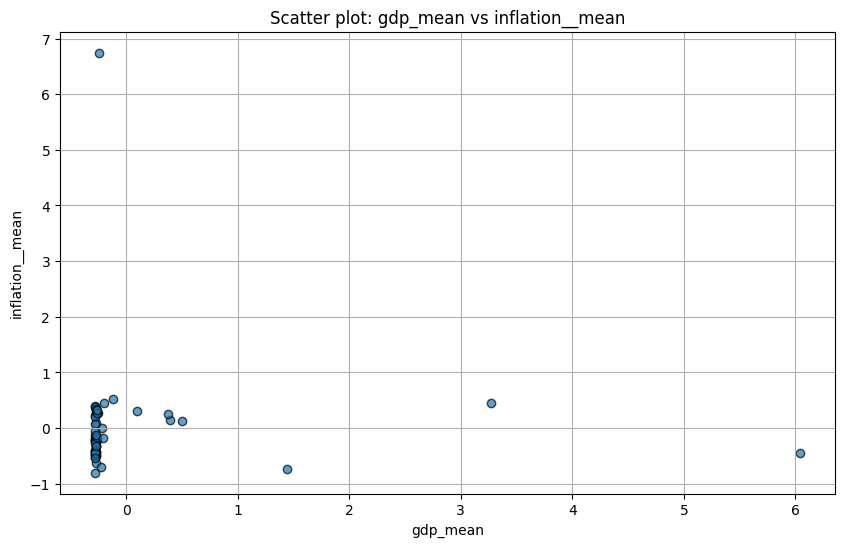

In [15]:
scatter_plot(df_scaled, 'gdp_mean', 'inflation__mean')

In [18]:
z_scores = np.abs(df_scaled[['inflation__mean', 'gdp_mean']])

In [19]:
outlier_mask = (z_scores > 3).any(axis=1)
outliers = df_scaled[outlier_mask]

In [22]:
outliers[['Country','inflation__mean', 'gdp_mean']]

,Country,inflation__mean,gdp_mean
7,Colombia,0.451283,3.270822
45,South Korea,-0.446643,6.037754
50,Turkey,6.747817,-0.243083


In [23]:
colombia_df = pd.read_parquet('../data/by_country/Colombia_macro_profile.parquet')

In [24]:
colombia_df['gdp'].mean()

np.float64(226433.57208333333)

In [26]:
colombia_df[['Year','gdp']]

,Year,gdp
0,2007,107126.5000
1,2008,119138.5000
2,2009,125393.5000
3,2010,136015.0000
4,2011,154755.7500
5,2012,166626.7500
6,2013,178523.2500
7,2014,190725.7475
8,2015,201173.0000
9,2016,215945.5025


In [28]:
one_point_countries[['Country','gdp_mean']]

,Country,gdp_mean
0,Australia,525.90025
1,Austria,100.90000
2,Belgium,124.25175
3,Brazil,2065.83350
4,Bulgaria,33.36100
5,Canada,607.98300
6,Chile,54722.46925
7,Colombia,289749.93000
8,Croatia,14.77000
9,Cyprus,6.12050


In [29]:
colombia_df[(colombia_df['Year'] >= 2015) & (colombia_df['Year'] <= 2024)]['gdp'].mean()

np.float64(289749.93)

<Axes: xlabel='gdp_mean', ylabel='Count'>

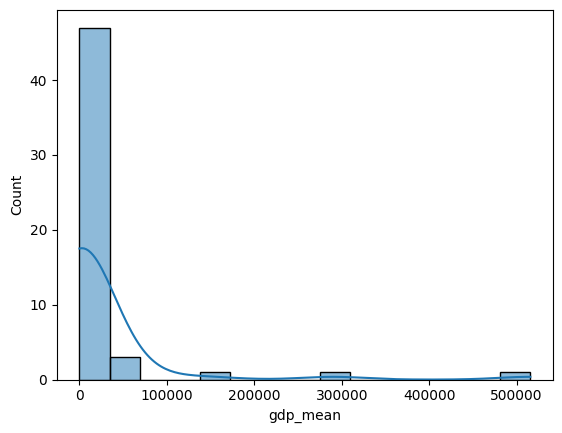

In [30]:
sns.histplot(one_point_countries['gdp_mean'], kde=True)

In [31]:
def columnas_con_outliers(df_scaled, threshold=3):
    columnas_outliers = []
    for col in df_scaled.select_dtypes(include='number').columns:
        z_scores = np.abs(df_scaled[col])
        if (z_scores > threshold).any():
            columnas_outliers.append(col)
    return columnas_outliers

In [32]:
outlier_cols = columnas_con_outliers(df_scaled)
print("Columnas con outliers:", outlier_cols)

Columnas con outliers: ['labor_force_mean', 'labor_force_median', 'labor_force_std', 'labor_force_min', 'labor_force_max', 'labor_force_last', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_median', 'livestock_prod_std', 'livestock_prod_min', 'livestock_prod_max', 'livestock_prod_kurtosis', 'agr_land_std', 'agr_land_cv', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_mean', 'gov_exp_median', 'gov_exp_std', 'gov_exp_cv', 'gov_exp_min', 'gov_exp_max', 'gov_exp_last', 'gov_exp_growth', 'gov_exp_skew', 'gov_exp_kurtosis', 'gov_exp_trend', 'reserves_mean', 'reserves_median', 'reserves_std', 'reserves_min', 'reserves_max', 'reserves_last', 'reserves_growth', 'reserves_skew', 'reserves_trend', 'investment_mean', 'investment_median', 'investment_std', 'investment_cv', 'investment_min', 'investment_max', 'investment_last', 'investment

In [47]:
df_log_transformed = one_point_countries.copy()

In [48]:
log_transform_cols = [
    'labor_force_mean', 'labor_force_median', 'labor_force_max', 'labor_force_last',
    'livestock_prod_max', 'livestock_prod_last',
    'gov_exp_mean', 'gov_exp_median', 'gov_exp_max', 'gov_exp_last',
    'reserves_mean', 'reserves_median', 'reserves_max', 'reserves_last',
    'investment_mean', 'investment_median', 'investment_max', 'investment_last',
    'cpi_mean', 'cpi_median', 'cpi_max', 'cpi_last',
    'gdp_mean', 'gdp_median', 'gdp_max', 'gdp_last',
    'priv_cred_mean', 'priv_cred_median', 'priv_cred_max', 'priv_cred_last',
    'unemployment_max', 'unemployment_last',
    'share_of_industry__max',
    'inflation__max', 'inflation__last'
]

for col in log_transform_cols:
    df_log_transformed[col] = np.log(df_log_transformed[col] + 1)  # +1 to avoid log(0)

In [49]:
df_combined = df_scaled.copy()

In [50]:
for col in log_transform_cols:
    if col in df_combined.columns:
        df_combined[col] = df_log_transformed[col]

<Axes: xlabel='gdp_mean', ylabel='Count'>

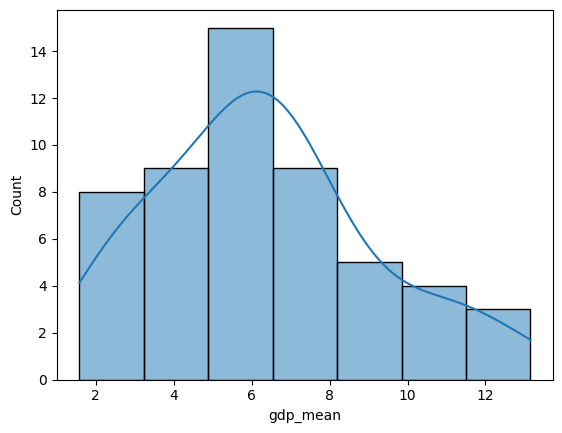

In [37]:
sns.histplot(df_combined['gdp_mean'], kde=True)

<Axes: xlabel='rule_of_law__growth', ylabel='Count'>

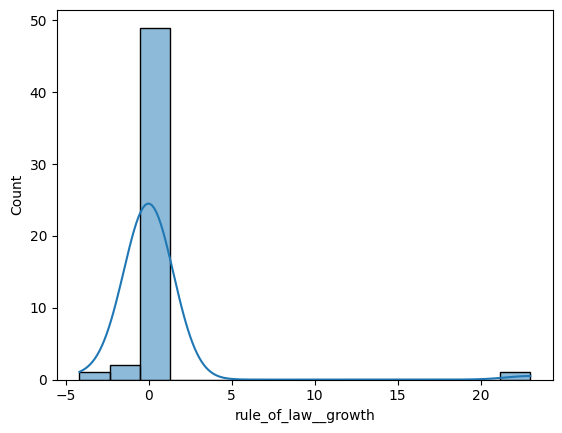

In [38]:
sns.histplot(df_combined['rule_of_law__growth'], kde=True)

In [39]:
def plot_outlier_histograms(df, outlier_cols, log_transform_cols, bins=30):
    # Filtrar columnas con outliers que no fueron log-transformadas
    cols_to_plot = [col for col in outlier_cols if col not in log_transform_cols]
    
    # Configurar tamaño de la cuadrícula
    n_cols = 3
    n_rows = (len(cols_to_plot) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    # Graficar cada histograma
    for i, col in enumerate(cols_to_plot):
        sns.histplot(df[col], bins=bins, kde=True, ax=axes[i], color='steelblue')
        axes[i].set_title(f'Distribution of {col}')
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Frequency')

    # Ocultar ejes vacíos si sobran
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()



In [40]:
plot_outlier_histograms(df_scaled, outlier_cols, log_transform_cols)

<Axes: xlabel='inflation__mean', ylabel='Count'>

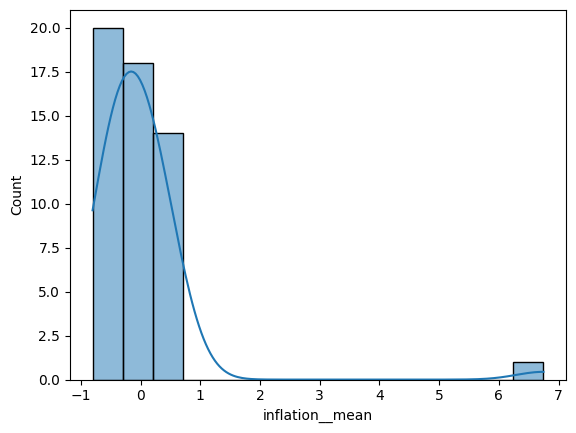

In [51]:
sns.histplot(df_combined['inflation__mean'], kde=True)

<Axes: xlabel='inflation__mean', ylabel='Count'>

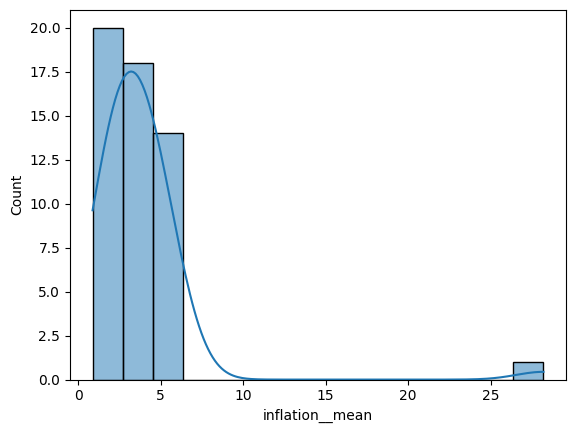

In [45]:
sns.histplot(one_point_countries['inflation__mean'], kde=True)



In [52]:
plot_outlier_histograms(one_point_countries, outlier_cols, log_transform_cols)

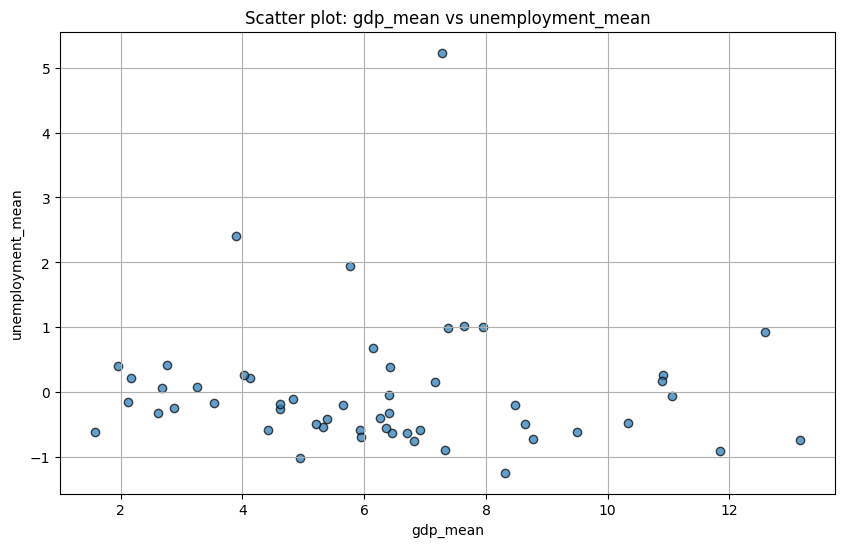

In [61]:
scatter_plot(df_combined, 'gdp_mean', 'unemployment_mean')

In [62]:
from mpl_toolkits.mplot3d import Axes3D

In [63]:
def scatter_plot_3d(df, x_col, y_col, z_col, color_col=None, title=None):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Color opcional por categoría o cluster
    if color_col:
        colors = df[color_col]
    else:
        colors = 'steelblue'

    ax.scatter(df[x_col], df[y_col], df[z_col], c=colors, alpha=0.7, edgecolors='k')

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_zlabel(z_col)
    ax.set_title(title if title else f'3D Scatter: {x_col}, {y_col}, {z_col}')
    plt.tight_layout()
    plt.show()

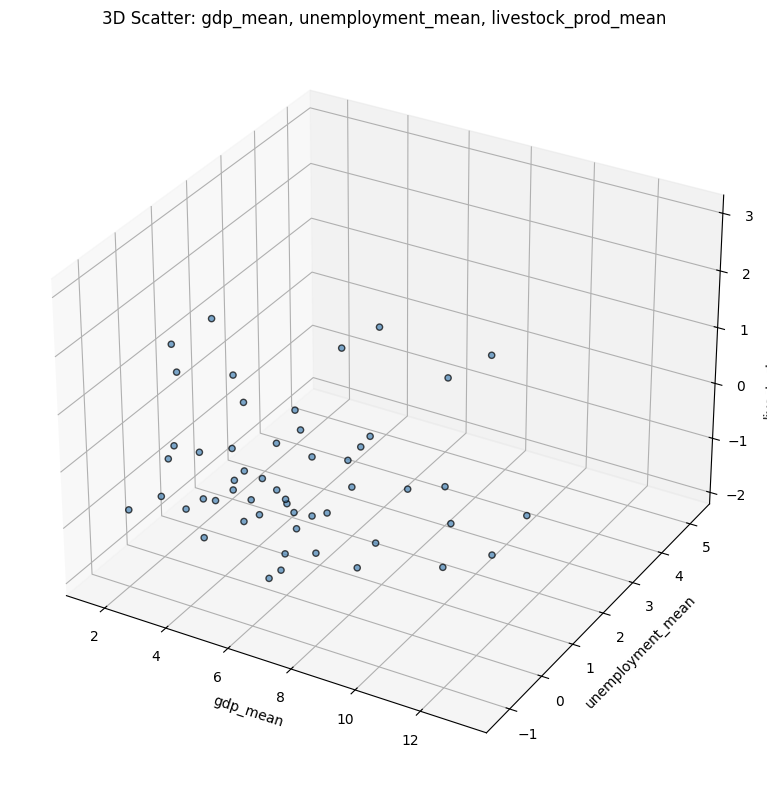

In [65]:
scatter_plot_3d(df_combined, 'gdp_mean', 'unemployment_mean', 'livestock_prod_mean')

In [66]:
from sklearn.cluster import KMeans

In [67]:
km = KMeans(n_clusters=3,
            init='random',
            n_init=10,
            max_iter=100,
            random_state=42)

In [68]:
df_combined.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,2.679788,2.679994,-0.139226,0.884957,-0.250769,2.740840,2.740840,1.016655,-0.044810,...,-1.514312,0.138675,0.997664,0.783123,0.991862,-0.183282,-0.557676,0.740819,0.517477,AUS
1,Austria,1.736775,1.731656,-0.254276,-0.654307,-0.363802,1.763017,1.763017,-0.171715,0.837722,...,-0.580068,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,1.592734,-0.060887,AUT
2,Belgium,1.825355,1.821318,-0.241488,-0.102542,-0.357845,1.859418,1.859418,0.220420,0.054900,...,0.512668,0.138675,0.428533,0.521389,0.272102,-0.262785,1.365494,-0.006636,-0.933542,BEL
3,Brazil,4.651376,4.653484,0.226805,-0.516466,0.953805,4.675629,4.673763,-0.294298,-1.001512,...,0.657131,0.138675,-1.728868,-1.724013,-1.808661,0.128118,0.887456,-1.022241,-0.947848,BRA
4,Bulgaria,1.448095,1.451614,-0.253629,-0.082573,-0.384303,1.477049,1.408545,-1.791026,-1.513620,...,0.904676,-7.211103,-1.305329,-1.172995,-1.023467,-0.313032,-1.526935,0.057350,-0.412401,BGR


In [69]:
df_cluster_input = df_combined.select_dtypes(include='number')

In [70]:
start_time = time.time()
km.fit(df_cluster_input)
end_time = time.time()

In [73]:
print(f"The time to convergence was: {round((end_time-start_time),2)} segs")

The time to convergence was: 1.82 segs


In [75]:
len(km.labels_)

53

In [76]:
df_combined['cluster'] = km.labels_

In [77]:
df_combined.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3,cluster
0,Australia,2.679788,2.679994,-0.139226,0.884957,-0.250769,2.740840,2.740840,1.016655,-0.044810,...,0.138675,0.997664,0.783123,0.991862,-0.183282,-0.557676,0.740819,0.517477,AUS,1
1,Austria,1.736775,1.731656,-0.254276,-0.654307,-0.363802,1.763017,1.763017,-0.171715,0.837722,...,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,1.592734,-0.060887,AUT,0
2,Belgium,1.825355,1.821318,-0.241488,-0.102542,-0.357845,1.859418,1.859418,0.220420,0.054900,...,0.138675,0.428533,0.521389,0.272102,-0.262785,1.365494,-0.006636,-0.933542,BEL,0
3,Brazil,4.651376,4.653484,0.226805,-0.516466,0.953805,4.675629,4.673763,-0.294298,-1.001512,...,0.138675,-1.728868,-1.724013,-1.808661,0.128118,0.887456,-1.022241,-0.947848,BRA,1
4,Bulgaria,1.448095,1.451614,-0.253629,-0.082573,-0.384303,1.477049,1.408545,-1.791026,-1.513620,...,-7.211103,-1.305329,-1.172995,-1.023467,-0.313032,-1.526935,0.057350,-0.412401,BGR,0


In [78]:
def plot_kmeans_clusters(df, x_col, y_col, model, cluster_col='cluster'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    y_km = df[cluster_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por cluster
    colors = ['lightgreen', 'orange', 'lightblue']
    markers = ['s', 'o', 'v']

    # Graficar cada cluster
    for i in range(model.n_clusters):
        plt.scatter(X[y_km == i, 0], X[y_km == i, 1],
                    s=50, c=colors[i], marker=markers[i],
                    edgecolor='black', label=f'Cluster {i+1}')

    # Graficar centroides
    plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
                s=250, marker='*', c='red', edgecolor='black', label='Centroids')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1)
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'K-Means Clustering: {x_col} vs {y_col}')
    plt.show()

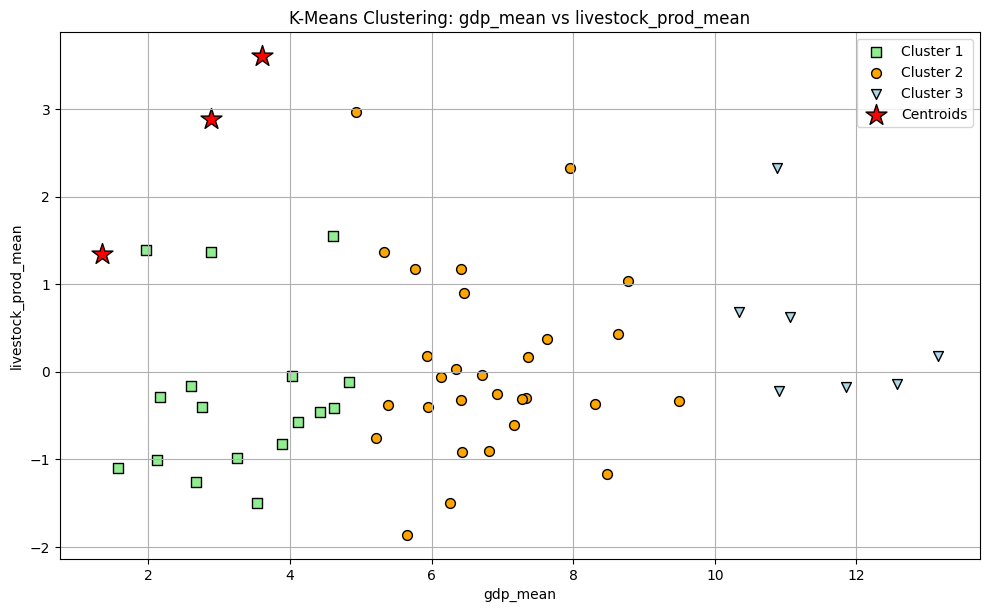

In [81]:
plot_kmeans_clusters(df_combined, 'gdp_mean', 'livestock_prod_mean', km)

In [82]:
countries_clusters_kmean_random = df_combined[['Country', 'iso_a3', 'cluster']]

In [83]:
countries_clusters_kmean_random.head()

,Country,iso_a3,cluster
0,Australia,AUS,1
1,Austria,AUT,0
2,Belgium,BEL,0
3,Brazil,BRA,1
4,Bulgaria,BGR,0


In [86]:
output_dir = '../data/clusters'

# Crear el directorio si no existe
os.makedirs(output_dir, exist_ok=True)

In [87]:
countries_clusters_kmean_random.to_parquet('../data/clusters/clusters_kmean_random.parquet')